# **CMSC 320 Final Project Checkpoint 2:**

# **Data Cleaning/Processing and Simple Analysis**

## Part 1.1: Data Preprocessing - Cleaning the Stock_Price.csv (stock_df dataframe)

In [128]:
import pandas as pd
from datetime import datetime
import string
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

#load the csv of product stock and product info
stock_df = pd.read_csv("Stock_Price.csv")
product_df = pd.read_csv("Product_Info.csv")

In [129]:
stock_df.head() # view format of original dataframe before preprocessing

,ID,Company_Name,Sector,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,52W_Low,52W_High,Description,CEO,Website
0,0,"Amazon.com, Inc.",Consumer Cyclical,Internet Retail United States,United States,Seattle,"$2,379,000,578,048",$222.54,226.19,161.38,258.60,"Amazon.com, Inc. eng...",NaN,NaN
1,1,ASUSTeK Computer Inc.,Technology,Computer Hardware,Taiwan,Taipei,"$435,257,507,840",$586.00,584.00,441.00,745.00,ASUSTeK Computer Inc...,Mr. Chongtang Shi,https://www.asus.com
2,6,Intel Corporation,Technology,Semiconductors,United States,Santa Clara,"$178,922,684,416",$37.51,37.81,17.67,44.02,Intel Corporation de...,Mr. Lip-Bu Tan,https://www.intel.com
3,7,HP Inc.,Technology,Computer Hardware,United States,Palo Alto,"$22,890,848,256",$24.49,24.74,21.21,35.28,HP Inc. provides per...,Mr. Enrique J. Lores,https://www.hp.com
4,8,Dell Technologies Inc.,Technology,Computer Hardware,United States,Round Rock,"$87,467,827,200",$130.51,129.98,66.25,168.08,Dell Technologies In...,Mr. Michael Saul Dell,https://www.dell.com


In [130]:
#cleaning stock

# value_counts() output shows that both Taipei and New Taipei City exist as a City in the dataset
print(stock_df["City"].value_counts())

#make City - taipei and new taipei city just New Taipei City
stock_df["City"] = stock_df["City"].replace("Taipei", "New Taipei City")

# value_counts() output shows that both Internet Retail United States and Internet Retail exist in the dataset
print(stock_df["Industry"].value_counts())

#make Industry - Internet Retail United States to Internet Retail
stock_df["Industry"] = stock_df["Industry"].replace("Internet Retail United States", "Internet Retail")

#Remove Sector, Website, CEO, Description columns

stock_df = stock_df.drop(columns=["Sector", "Website", "CEO", "Description", "ID"])
stock_df["Past_Year_Low"] = stock_df["52W_Low"]
stock_df = stock_df.drop(columns="52W_Low")
stock_df["Past_Year_High"] = stock_df["52W_High"]
stock_df = stock_df.drop(columns="52W_High")

#Remove dollar signs, make all dollar values floats

stock_df ["Market_Value"] = (stock_df["Market_Value"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))

stock_df ["Current_Price"] = (stock_df["Current_Price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))

#remove duplicate rows
stock_df.drop_duplicates(inplace=True)

#Display the dataset
stock_df



City
Santa Clara        4
San Jose           3
Seattle            2
Palo Alto          2
New Taipei City    2
Cupertino          2
Taipei             1
Round Rock         1
Quarry Bay         1
Suwon              1
Tokyo              1
Redmond            1
Kadoma             1
Seoul              1
Milpitas           1
Lausanne           1
Mountain View      1
Name: count, dtype: int64
Industry
Computer Hardware                 11
Consumer Electronics               6
Semiconductors                     4
Internet Retail United States      1
Software - Infrastructure          1
Communication Equipment            1
Internet Content & Information     1
Internet Retail                    1
Name: count, dtype: int64


,Company_Name,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,Past_Year_Low,Past_Year_High
0,"Amazon.com, Inc.",Internet Retail,United States,Seattle,2379000578048.00,222.54,226.19,161.38,258.60
1,ASUSTeK Computer Inc.,Computer Hardware,Taiwan,New Taipei City,435257507840.00,586.00,584.00,441.00,745.00
2,Intel Corporation,Semiconductors,United States,Santa Clara,178922684416.00,37.51,37.81,17.67,44.02
3,HP Inc.,Computer Hardware,United States,Palo Alto,22890848256.00,24.49,24.74,21.21,35.28
4,Dell Technologies Inc.,Computer Hardware,United States,Round Rock,87467827200.00,130.51,129.98,66.25,168.08
5,Lenovo Group Limited,Computer Hardware,Hong Kong,Quarry Bay,15170897920.00,24.46,24.50,17.84,35.09
6,Acer Incorporated,Computer Hardware,Taiwan,New Taipei City,79514206208.00,26.45,26.70,26.20,40.95
7,Apple Inc.,Consumer Electronics,United States,Cupertino,4067898949632.00,274.11,278.28,169.21,288.62
9,"Samsung Electronics Co., Ltd.",Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
10,Sony Group Corporation,Consumer Electronics,Japan,Tokyo,158866636800.00,26.64,26.77,19.85,30.34


In [131]:
# Verifying that there are no NaN values
print(stock_df.isna().sum())

Company_Name      0
Industry          0
Nation            0
City              0
Market_Value      0
Current_Price     0
Previous_Close    0
Past_Year_Low     0
Past_Year_High    0
dtype: int64


## Part 1.2: Data Preprocessing - Cleaning the Product_Info.csv (product_df dataframe)

In [132]:
# view format of original dataframe before preprocessing
print(product_df.columns)
product_df.head()

Index(['id', 'prices.amountMax', 'prices.amountMin', 'prices.availability',
       'prices.condition', 'prices.currency', 'prices.dateSeen',
       'prices.isSale', 'prices.merchant', 'prices.shipping',
       'prices.sourceURLs', 'asins', 'brand', 'categories', 'dateAdded',
       'dateUpdated', 'ean', 'keys', 'manufacturer', 'manufacturerNumber',
       'name', 'primaryCategories', 'upc', 'weight'],
      dtype='str')


,id,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.dateSeen,prices.isSale,prices.merchant,prices.shipping,...,dateAdded,dateUpdated,ean,keys,manufacturer,manufacturerNumber,name,primaryCategories,upc,weight
0,AWOpOCd2YSSHbkXw07ei,224.99,224.99,TRUE,new,USD,2018-05-26T13:00:00Z,True,Bestbuy.com,NaN,...,2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,NaN,"887276057491,samsung850pro512gbinternalsataiii...",NaN,MZ-7KE512BW,Samsung - 850 PRO 512GB Internal SATA III Soli...,Electronics,8.87E+11,0.14 ounces
1,AWOpOCd2YSSHbkXw07ei,249.99,249.99,TRUE,new,USD,2018-05-26T13:00:00Z,False,Bestbuy.com,NaN,...,2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,NaN,"887276057491,samsung850pro512gbinternalsataiii...",NaN,MZ-7KE512BW,Samsung - 850 PRO 512GB Internal SATA III Soli...,Electronics,8.87E+11,0.14 ounces
2,AV2Z1Efc-jtxr-f39lm6,139.99,139.99,Yes,New,USD,"2017-07-31T23:00:00Z,2017-07-26T21:00:00Z",False,Bestbuy.com,NaN,...,2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,NaN,"corsair/cmk16gx4m2b3000c15,843591070010,corsai...",NaN,CMK16GX4M2B3000C15,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Electronics,8.44E+11,3.2 ounces
3,AV2Z1Efc-jtxr-f39lm6,162.99,162.99,Yes,New,USD,2017-10-10T13:00:00Z,False,Bestbuy.com,NaN,...,2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,NaN,"corsair/cmk16gx4m2b3000c15,843591070010,corsai...",NaN,CMK16GX4M2B3000C15,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Electronics,8.44E+11,3.2 ounces
4,AV2Z1Efc-jtxr-f39lm6,189.99,189.99,TRUE,new,USD,2018-05-26T08:00:00Z,False,Bestbuy.com,NaN,...,2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,NaN,"corsair/cmk16gx4m2b3000c15,843591070010,corsai...",NaN,CMK16GX4M2B3000C15,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Electronics,8.44E+11,3.2 ounces


In [133]:
#reorder brand column to be first column in csv, and remove non essential columns
product_df = product_df[["brand", "prices.amountMax", "prices.amountMin", "prices.availability", "prices.condition", "prices.currency", "prices.merchant", "categories", "dateAdded", "dateUpdated", "name"]]

print("Value Counts Before Standardizing Values:")
print(product_df["prices.condition"].value_counts())
print(product_df["prices.availability"].value_counts())

#standardize prices.availability and price condition

product_df["prices.condition"] = product_df["prices.condition"].replace(["New", "New other (see details)"], "new")
product_df["prices.condition"] = product_df["prices.condition"].replace(["Refurbished", "Used", "used", "Seller refurbished", "Manufacturer refurbished", "pre-owned", "For parts or not working"], "refurbished")

product_df["prices.condition"] = product_df["prices.condition"].replace("Magnet - Neodymium, SearsCondition - Refurbished, Refresh Rate - 4Hz - 100kHz, Headphone Type - Over the Head, Driver Unit - 70mm, Power " \
"Handling (Watts) - 2000mW, Plug Type - 3.5mm, Audio Accessories - Headphones, Headphone Uses - Audiophile; iPod, Color - Black; Black, Impedance - 70 ohm, Cable Length - 6 - 6.99 Feet; 9 - 9.99 Feet, Sensitivity - " \
"102dB, Headphone Styles - Over-ear", "refurbished")

product_df["prices.availability"] = product_df["prices.availability"].replace(["TRUE", "yes", "Yes", "In Stock", "Special Order", "Limited Stock"], "in stock")
product_df["prices.availability"] = product_df["prices.availability"].replace(["no", "No", "Discontinued", "Not In Stock", "More on the Way", "Out Of Stock", "sold"], "out of stock")
product_df["prices.availability"] = product_df["prices.availability"].replace("undefined", "unknown")

# Fill NaN values in categorial data columns with "unknown"
categorical_cols = ["brand", "prices.availability", "prices.condition", "prices.merchant", "categories"]
product_df[categorical_cols] = (product_df[categorical_cols].fillna("unknown"))

Value Counts Before Standardizing Values:
prices.condition
New                                                                                                                                                                                                                                                                                                                                                                                                  4834
new                                                                                                                                                                                                                                                                                                                                                                                                   529
Used                                                                                                                                                     

In [134]:
print("\nValue Counts After Standardizing Values:")
print(product_df["prices.condition"].value_counts())
print(product_df["prices.availability"].value_counts())


Value Counts After Standardizing Values:
prices.condition
new            5528
unknown         617
refurbished     465
Name: count, dtype: int64
prices.availability
in stock        5643
unknown          754
out of stock     213
Name: count, dtype: int64


In [135]:
print("stock_df company names:")
print(stock_df["Company_Name"].unique())

print("\nproduct_df company names:")
print(product_df["brand"].unique())

stock_df company names:
<ArrowStringArray>
[                  'Amazon.com, Inc.',              'ASUSTeK Computer Inc.',
                  'Intel Corporation',                            'HP Inc.',
             'Dell Technologies Inc.',               'Lenovo Group Limited',
                  'Acer Incorporated',                         'Apple Inc.',
      'Samsung Electronics Co., Ltd.',             'Sony Group Corporation',
 'Micro-Star International Co., Ltd.',              'Microsoft Corporation',
     'Panasonic Holdings Corporation',                'LG Electronics Inc.',
       'Advanced Micro Devices, Inc.',               'Corsair Gaming, Inc.',
        'Western Digital Corporation',        'Logitech International S.A.',
                 'NVIDIA Corporation',                      'NETGEAR, Inc.',
                      'Alphabet Inc.']
Length: 21, dtype: str

product_df company names:
<ArrowStringArray>
[        'Samsung',         'Corsair',              'WD',       'Microsoft',
  

In [136]:
#standardize company names across the two datasets

# Maps from original brand names in product_df to their corresponding equivalents in stock_df
brand_mappings = {
    "amazon" : "Amazon.com, Inc.",
    "asus": "ASUSTeK Computer Inc.",
    "intel": "Intel Corporation",
    "hp": "HP Inc.",
    "dell": "Dell Technologies Inc.",
    "lenovo": "Lenovo Group Limited",
    "acer": "Acer Incorporated",
    "apple": "Apple Inc.",
    "samsung": "Samsung Electronics Co., Ltd.",
    "sony": "Sony Group Corporation",
    "msi": "Micro-Star International Co., Ltd.",
    "microsoft": "Microsoft Corporation",
    "lg": "LG Electronics Inc.",
    "amd": "Advanced Micro Devices, Inc.",
    "corsair": "Corsair Gaming, Inc.",
    "western digital": "Western Digital Corporation",
    "wd": "Western Digital Corporation",
    "logitech": "Logitech International S.A.",
    "nvidia": "NVIDIA Corporation",
    "netgear": "NETGEAR, Inc.",
    "google": "Alphabet Inc.",
    "panasonic": "Panasonic Holdings Corporation"
}

product_df["brand"] = product_df["brand"].str.lower().replace(brand_mappings)

#remove all products not produced by the focused on companies
product_df = product_df[product_df["brand"].isin(stock_df["Company_Name"])].reset_index(drop=True)

#remove all products not in usd
product_df = product_df[product_df["prices.currency"] == "USD"].reset_index(drop=True)

print("product_df new company names:")
print(product_df["brand"].unique())

product_df.head(10)

product_df new company names:
<ArrowStringArray>
[     'Samsung Electronics Co., Ltd.',               'Corsair Gaming, Inc.',
        'Western Digital Corporation',              'Microsoft Corporation',
                         'Apple Inc.',               'Lenovo Group Limited',
             'Sony Group Corporation',        'Logitech International S.A.',
              'ASUSTeK Computer Inc.',             'Dell Technologies Inc.',
                      'NETGEAR, Inc.',     'Panasonic Holdings Corporation',
                'LG Electronics Inc.', 'Micro-Star International Co., Ltd.',
                  'Acer Incorporated',                            'HP Inc.',
                 'NVIDIA Corporation',                  'Intel Corporation',
                      'Alphabet Inc.',                   'Amazon.com, Inc.',
       'Advanced Micro Devices, Inc.']
Length: 21, dtype: str


,brand,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.merchant,categories,dateAdded,dateUpdated,name
0,"Samsung Electronics Co., Ltd.",224.99,224.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...
1,"Samsung Electronics Co., Ltd.",249.99,249.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...
2,"Corsair Gaming, Inc.",139.99,139.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
3,"Corsair Gaming, Inc.",162.99,162.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
4,"Corsair Gaming, Inc.",189.99,189.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
5,"Corsair Gaming, Inc.",194.82,194.82,in stock,new,USD,Beach Audio Inc,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
6,"Corsair Gaming, Inc.",149.99,149.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
7,"Corsair Gaming, Inc.",147.99,147.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
8,"Corsair Gaming, Inc.",158.95,158.95,in stock,new,USD,Alex Magic Electronics,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
9,"Corsair Gaming, Inc.",154.99,154.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...


## Part 1.3: Data Procesing - Combining the two .csv files into one

In [137]:
combined_df = product_df.merge(stock_df, left_on="brand", right_on="Company_Name", how="inner")
combined_df = combined_df.drop(columns=["Company_Name"])

combined_df.head(10)

,brand,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.merchant,categories,dateAdded,dateUpdated,name,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,Past_Year_Low,Past_Year_High
0,"Samsung Electronics Co., Ltd.",224.99,224.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...,Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
1,"Samsung Electronics Co., Ltd.",249.99,249.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...,Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
2,"Corsair Gaming, Inc.",139.99,139.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
3,"Corsair Gaming, Inc.",162.99,162.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
4,"Corsair Gaming, Inc.",189.99,189.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
5,"Corsair Gaming, Inc.",194.82,194.82,in stock,new,USD,Beach Audio Inc,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
6,"Corsair Gaming, Inc.",149.99,149.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
7,"Corsair Gaming, Inc.",147.99,147.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
8,"Corsair Gaming, Inc.",158.95,158.95,in stock,new,USD,Alex Magic Electronics,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
9,"Corsair Gaming, Inc.",154.99,154.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02


## Part 2.1: Simple Analysis - 

count    6256.00
mean      750.81
std      1191.85
min         1.00
25%       127.99
50%       338.99
75%       949.24
max     19999.99
Name: avg_price, dtype: float64


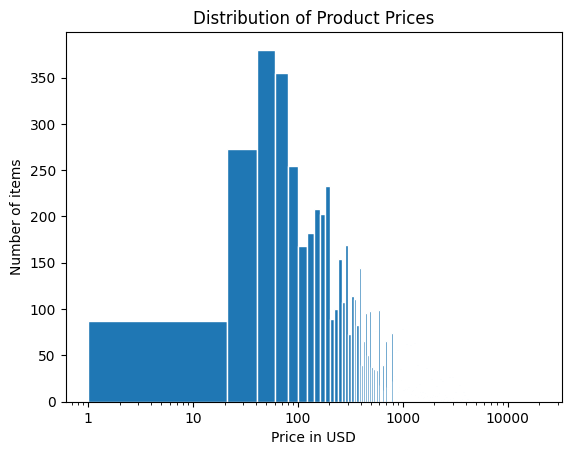

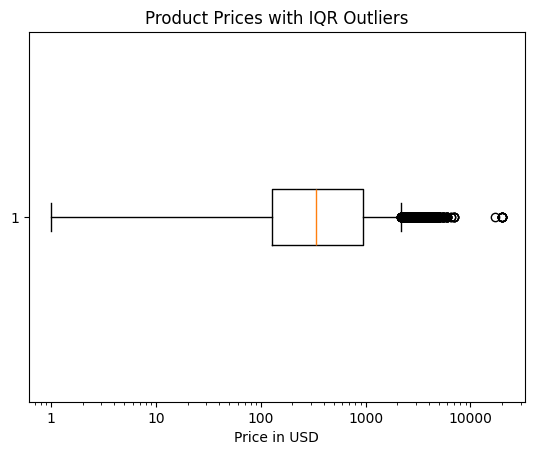

In [138]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc

#calculate the average prive for each item
combined_df["avg_price"] = (combined_df["prices.amountMin"] + combined_df["prices.amountMax"]) / 2
price = combined_df["avg_price"]

#descriptive statistics for price 
print(price.describe())


plt.xscale("log")
plt.hist(price, bins= 1000, edgecolor="white")
plt.xscale("log")
plt.title("Distribution of Product Prices")
plt.xlabel("Price in USD")
plt.ylabel("Number of items")
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
plt.show()

plt.boxplot(price, orientation="horizontal")
plt.xscale("log")
plt.title("Product Prices with IQR Outliers")
plt.xlabel("Price in USD")
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
plt.show()

## Part 2.2: 